# code_161 · Semi-supervision under a changed unlabelled regime

**Book:** section 31.1. A self-contained limited-label learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_31_GUIDE.md), [run evidence](../CHAPTER_31_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_161).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json,copy,hashlib
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=4261;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 4261


<a id="semi-supervised-assumptions"></a>
 ## Four real fitting mechanisms with one scarce-label budget
 Twelve labelled source buildings contribute two members each. Two hundred other buildings provide unlabelled measurements. Forty development and one hundred final buildings are distinct. Measurements form two curved groups; a supplied operating-regime flag changes the outcome rule in a new regime. Source labels contain only the familiar regime. Compare a group-calibrated RBF SVC, one-round confident pseudo-labelling, native graph label propagation and an original neural mean-teacher consistency fit. Each gets exactly 24 observed source labels. Compare two fixed unlabelled pools: familiar only or half from the changed regime. All configurations are fixed before final reporting, so the 80 development labels are diagnostic rather than selection evidence. Graph smoothness and consistency do not supply the missing new-regime label semantics.


,pool,method,development_accuracy,final_accuracy,familiar_final_accuracy,changed_final_accuracy,final_Brier
0,Familiar pool,Supervised,0.5125,0.520,0.90,0.14,0.531683
1,Familiar pool,Pseudo-label,0.5125,0.505,0.91,0.10,0.720164
2,Familiar pool,Graph,0.5000,0.440,0.84,0.04,0.723091
3,Familiar pool,Consistency,0.5250,0.480,0.86,0.10,0.953446
4,Mixed pool,Supervised,0.5125,0.520,0.90,0.14,0.531683
5,Mixed pool,Pseudo-label,0.5125,0.515,0.91,0.12,0.675282
6,Mixed pool,Graph,0.5000,0.445,0.87,0.02,0.653733
7,Mixed pool,Consistency,0.5000,0.460,0.86,0.06,1.004099


,pool,unlabelled_records,pseudo_labels_admitted,hidden_pseudo_error_for_audit_only
0,Familiar pool,400,311,0.006431
1,Mixed pool,400,153,0.006536


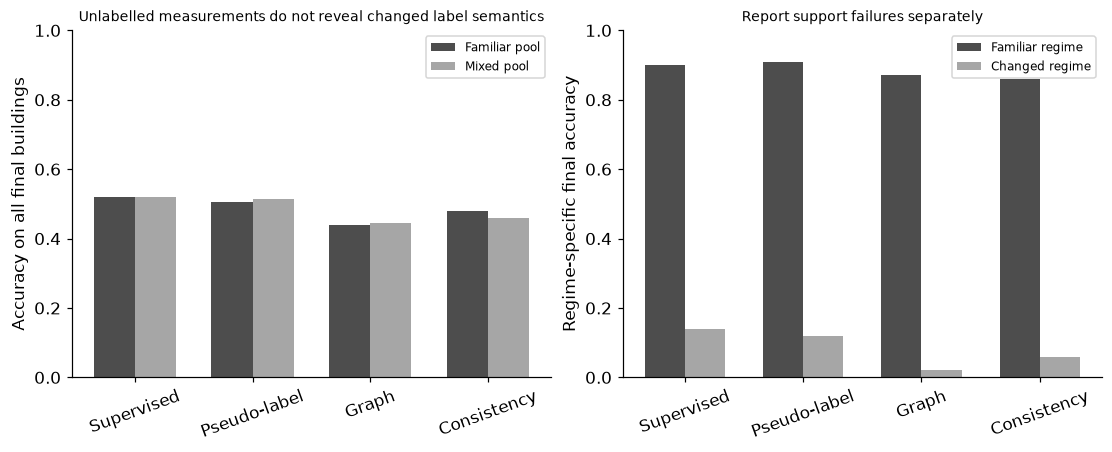

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GroupKFold
from sklearn.semi_supervised import LabelPropagation
def cohort(n,offset,changed_fraction=0.):
    groups=np.repeat(np.arange(offset,offset+n),2);class_id=np.repeat(np.arange(n)%2,2);angles=np.repeat(rng.uniform(0,np.pi,n),2)+rng.normal(0,.04,2*n);regime=np.repeat((np.arange(n)>=int(n*(1-changed_fraction))).astype(int),2);x=np.column_stack([np.where(class_id==0,np.cos(angles),1-np.cos(angles)),np.where(class_id==0,np.sin(angles),.5-np.sin(angles)),regime]);x[:,:2]+=rng.normal(0,.10,(2*n,2));y=class_id^regime;return x,y,groups
sx,sy,sg=cohort(12,0);dx,dy,dg=cohort(40,1000,.5);fx,fy,fg=cohort(100,2000,.5);scaler=StandardScaler().fit(sx);S=scaler.transform(sx);D=scaler.transform(dx);F=scaler.transform(fx);assert not set(sg)&(set(dg)|set(fg)) and not set(dg)&set(fg)
def svm(X,y,groups):
    folds=list(GroupKFold(3).split(X,y,groups));assert all(not set(groups[a])&set(groups[b]) for a,b in folds);return CalibratedClassifierCV(SVC(C=5,gamma=1.,random_state=SEED),cv=folds,ensemble=False).fit(X,y)
supervised=svm(S,sy,sg);base_p=supervised.predict_proba(F);rows=[];pseudo_rows=[];fitted={};traces={}
def consistency_fit(U):
    torch.manual_seed(SEED);student=nn.Sequential(nn.Linear(3,24),nn.Tanh(),nn.Linear(24,2));teacher=copy.deepcopy(student);opt=torch.optim.Adam(student.parameters(),lr=.01);X=torch.tensor(S);Y=torch.tensor(sy);Z=torch.tensor(U);generator=torch.Generator().manual_seed(SEED+2);trace=[]
    for step in range(500):
        ids=torch.randint(len(U),(64,),generator=generator);batch=Z[ids];noise=torch.randn((64,3),generator=generator)*torch.tensor([.04,.04,0.]);other_noise=torch.randn((64,3),generator=generator)*torch.tensor([.04,.04,0.])
        with torch.no_grad():target=teacher(batch+noise).softmax(1)
        supervised_loss=nn.functional.cross_entropy(student(X),Y);consistency=nn.functional.mse_loss(student(batch+other_noise).softmax(1),target);loss=supervised_loss+min(1.,step/100)*consistency;opt.zero_grad();loss.backward();opt.step()
        with torch.no_grad():
            for a,b in zip(teacher.parameters(),student.parameters()):a.mul_(.95).add_(b,alpha=.05)
        if (step+1)%50==0:trace.append((step+1,float(loss.detach())))
    with torch.no_grad():p=teacher(torch.tensor(F)).softmax(1).numpy();dev=teacher(torch.tensor(D)).softmax(1).numpy()
    return p,dev,trace
for name,fraction in [('Familiar pool',0.),('Mixed pool',.5)]:
    ux,uy,ug=cohort(200,3000 if fraction==0 else 4000,fraction);U=scaler.transform(ux);assert not set(ug)&(set(sg)|set(dg)|set(fg));up=supervised.predict_proba(U);accepted=up.max(1)>=.85;pseudo=svm(np.vstack([S,U[accepted]]),np.r_[sy,up.argmax(1)[accepted]],np.r_[sg,ug[accepted]]) if accepted.any() else supervised
    graph=LabelPropagation(kernel='rbf',gamma=2.,max_iter=1000,tol=1e-5).fit(np.vstack([S,U]),np.r_[sy,np.full(len(U),-1)]);cp,cd,trace=consistency_fit(U);traces[name]=trace;predictions={'Supervised':(base_p,supervised.predict_proba(D)),'Pseudo-label':(pseudo.predict_proba(F),pseudo.predict_proba(D)),'Graph':(graph.predict_proba(F),graph.predict_proba(D)),'Consistency':(cp,cd)}
    pseudo_rows.append({'pool':name,'unlabelled_records':len(U),'pseudo_labels_admitted':int(accepted.sum()),'hidden_pseudo_error_for_audit_only':float(np.mean(up.argmax(1)[accepted]!=uy[accepted])) if accepted.any() else None})
    for method,(p,pdev) in predictions.items():
        assert np.isfinite(p).all();pred=p.argmax(1);rows.append({'pool':name,'method':method,'development_accuracy':float(np.mean(pdev.argmax(1)==dy)),'final_accuracy':float(np.mean(pred==fy)),'familiar_final_accuracy':float(np.mean(pred[fx[:,2]==0]==fy[fx[:,2]==0])),'changed_final_accuracy':float(np.mean(pred[fx[:,2]==1]==fy[fx[:,2]==1])),'final_Brier':float(np.mean(np.sum((p-np.eye(2)[fy])**2,1)))});fitted[(name,method)]=p
RESULTS.update(labelled_source_buildings=12,true_source_labels=24,unlabelled_buildings_per_pool=200,development_buildings=40,development_labels=80,final_buildings=100,final_labels=200,pseudo_threshold=.85,consistency_updates=500,ema_decay=.95,metrics=rows,pseudo_label_audit=pseudo_rows,final_labels_used_for_fit_or_selection=0,development_labels_used_for_selection=0);display(pd.DataFrame(rows));display(pd.DataFrame(pseudo_rows))
fig,axes=plt.subplots(1,2,figsize=(10,4));methods=['Supervised','Pseudo-label','Graph','Consistency'];xx=np.arange(4)
for i,pool in enumerate(['Familiar pool','Mixed pool']):
    rr=[r for r in rows if r['pool']==pool];axes[0].bar(xx+(i-.5)*.35,[r['final_accuracy'] for r in rr],width=.35,color=['.3','.65'][i],label=pool)
axes[0].set(xticks=xx,xticklabels=methods,ylim=(0,1),ylabel='Accuracy on all final buildings',title='Unlabelled measurements do not reveal changed label semantics');axes[0].tick_params(axis='x',rotation=20);axes[0].legend(fontsize=8)
rr=[r for r in rows if r['pool']=='Mixed pool'];axes[1].bar(xx-.17,[r['familiar_final_accuracy'] for r in rr],width=.34,color='.3',label='Familiar regime');axes[1].bar(xx+.17,[r['changed_final_accuracy'] for r in rr],width=.34,color='.65',label='Changed regime');axes[1].set(xticks=xx,xticklabels=methods,ylim=(0,1),ylabel='Regime-specific final accuracy',title='Report support failures separately');axes[1].tick_params(axis='x',rotation=20);axes[1].legend(fontsize=8);plt.show()


<a id="derived-inferred-and-acquired-targets"></a>
 ## Supervision sources have different epistemic roles
 Hidden generated unlabelled outcomes are opened only after fitting to audit pseudo-label mistakes; they never select examples or tune methods. Graph inference is inductive for new final records: final measurements are not inserted into the fitted graph. Mean Teacher maintains an exponential moving average of student weights and penalizes disagreement under small measurement noise. The regime flag is not corrupted. No augmentation is assumed to preserve labels across the changed operating rule. Source-only scaling has no observed variation in the flag, making its unsupported new value explicit. The second figure contrasts self-derived, inferred and acquired supervision without calling any of them new independent truth.


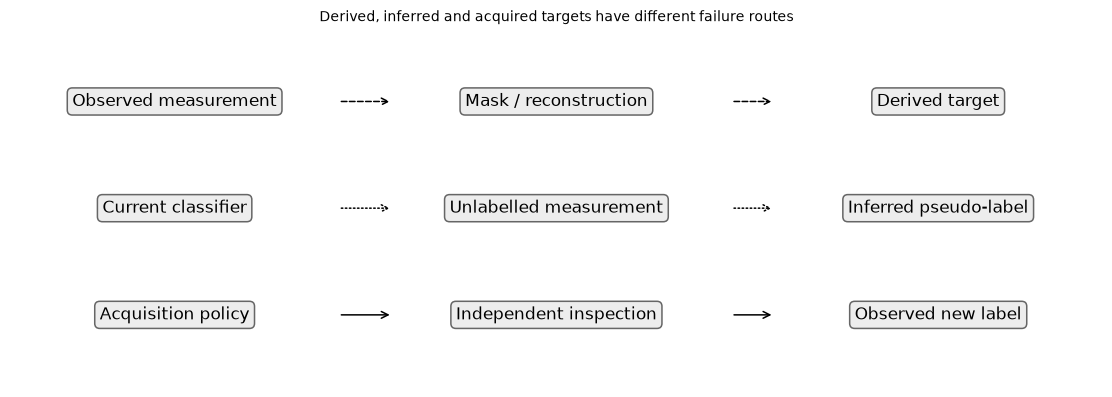

In [3]:
fig,ax=plt.subplots(figsize=(10,3.5));ax.axis('off');ys=[.8,.5,.2];items=[('Observed measurement','Mask / reconstruction','Derived target','--'),('Current classifier','Unlabelled measurement','Inferred pseudo-label',':'),('Acquisition policy','Independent inspection','Observed new label','-')]
for y,(left,middle,right,style) in zip(ys,items):
    for x,text in zip([.15,.5,.85],[left,middle,right]):ax.text(x,y,text,ha='center',va='center',transform=ax.transAxes,bbox={'boxstyle':'round,pad=.3','facecolor':'.93','edgecolor':'.4'})
    for a,b in [(.30,.35),(.66,.70)]:ax.annotate('',xy=(b,y),xytext=(a,y),xycoords='axes fraction',arrowprops={'arrowstyle':'->','linestyle':style})
ax.set_title('Derived, inferred and acquired targets have different failure routes');plt.show()
assert len(rows)==8 and len(pseudo_rows)==2 and RESULTS['true_source_labels']==24


In [4]:
summary={'example_id':'code_161','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual supervised pseudo-label graph and mean-teacher consistency fitting', 'same scarce source labels and source-only scaling', 'whole-building labelled unlabelled development and final roles', 'matched versus changed unlabelled operating regimes', 'pseudo-label mistakes and regime-specific final assessment retained'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual supervised pseudo-label graph and mean-teacher consistency fitting", "same scarce source labels and source-only scaling", "whole-building labelled unlabelled development and final roles", "matched versus changed unlabelled operating regimes", "pseudo-label mistakes and regime-specific final assessment retained"], "elapsed_seconds": 1.134, "example_id": "code_161", "hardware": "Darwin arm64 CPU", "results": {"consistency_updates": 500, "development_buildings": 40, "development_labels": 80, "development_labels_used_for_selection": 0, "ema_decay": 0.95, "final_buildings": 100, "final_labels": 200, "final_labels_used_for_fit_or_selection": 0, "labelled_source_buildings": 12, "metrics": [{"changed_final_accuracy": 0.14, "development_accuracy": 0.5125, "familiar_final_accuracy": 0.9, "final_Brier": 0.5316833532955788, "final_accuracy": 0.52, "method": "Supervised", "pool": "Familiar pool"}, {"changed_final_accuracy": 0.1, "development